# 3. Interpretabilidad del modelo

Analizamos el modelo campeon (XGBoost) con tecnicas **globales** y
**locales** vistas en el curso (Sesiones 5, 6 y 8):

- **Globales**: SHAP summary plot (importancia + direccion del efecto),
  Partial Dependence Plots (PDP).
- **Locales**: SHAP waterfall para casos individuales, LIME como
  contraste, y un contrafactual accionable con DiCE.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import PartialDependenceDisplay

from src.config import MODEL_PATH, PROCESSED_DTYPES, REFERENCE_DATA_PATH, TARGET_COL
from src.metrics import classification_metrics

payload = joblib.load(MODEL_PATH)
model, FEATURES = payload["model"], payload["features"]

reference = pd.read_csv(REFERENCE_DATA_PATH, dtype=PROCESSED_DTYPES)
X = reference[FEATURES]
y = reference[TARGET_COL]

# Muestra para que SHAP/LIME corran en tiempo razonable sobre datasets grandes.
X_sample = X.sample(n=min(20000, len(X)), random_state=42)

## 3.1 Interpretabilidad global — SHAP

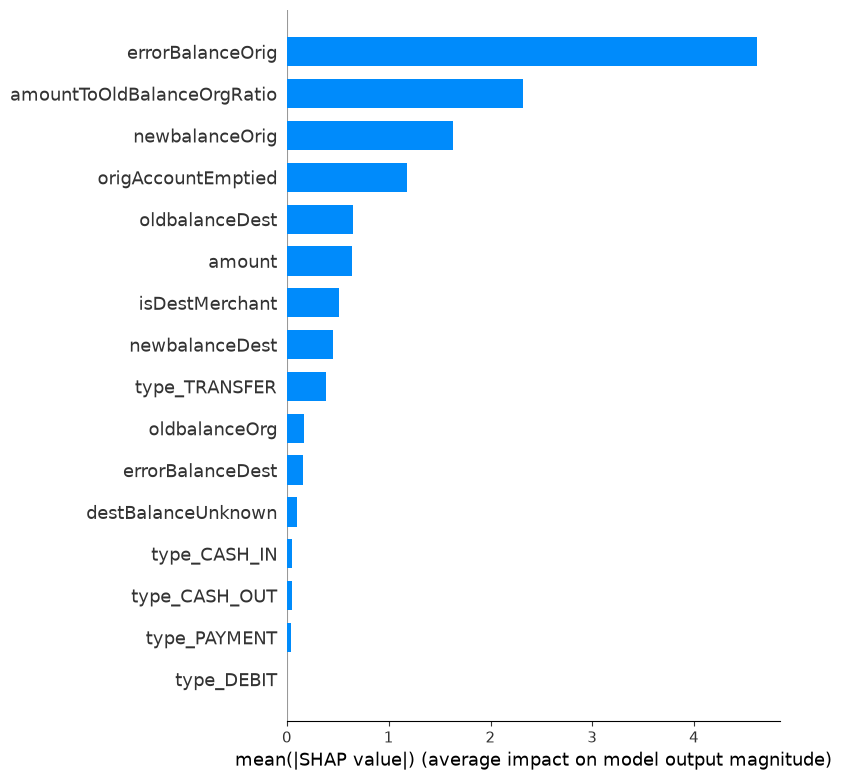

In [2]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("../reports/shap_summary_bar.png", bbox_inches="tight")
plt.show()

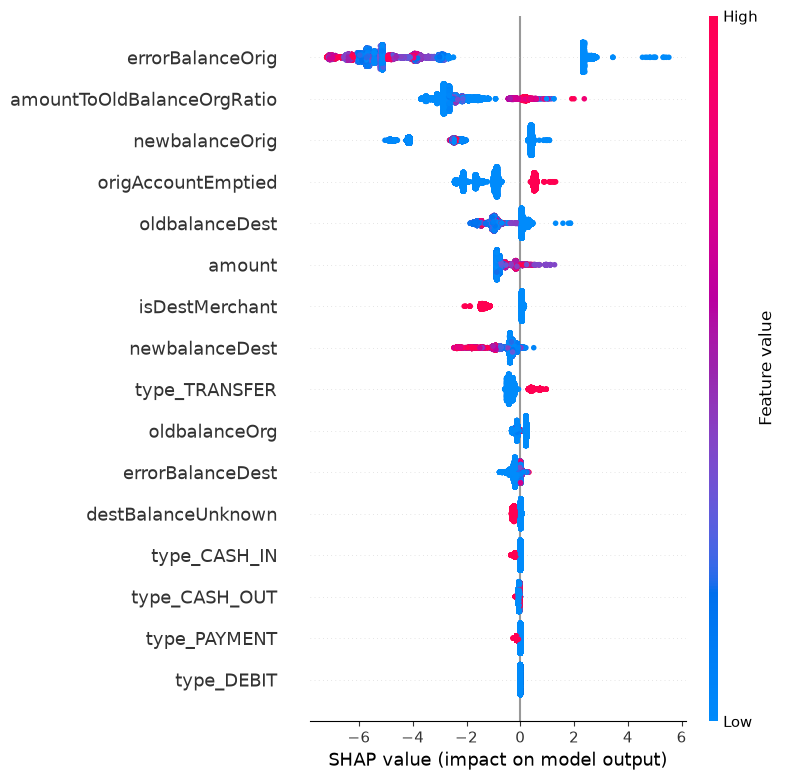

In [3]:
shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.savefig("../reports/shap_summary_beeswarm.png", bbox_inches="tight")
plt.show()

## 3.2 Interpretabilidad global — Partial Dependence Plots

Se inspeccionan las 3 features con mayor importancia SHAP.

Top features: ['errorBalanceOrig', 'amountToOldBalanceOrgRatio', 'newbalanceOrig']


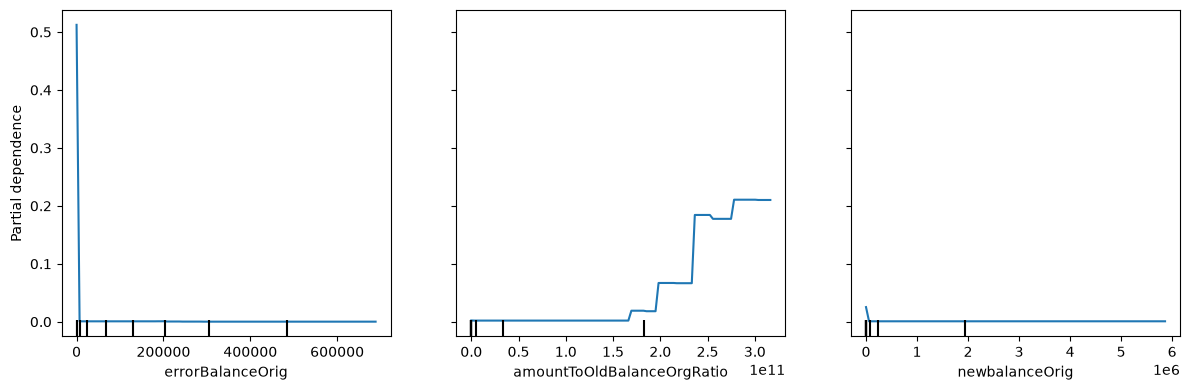

In [4]:
top_features = pd.Series(abs(shap_values).mean(axis=0), index=FEATURES).sort_values(ascending=False).head(3).index.tolist()
print("Top features:", top_features)

fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(model, X_sample, top_features, ax=ax)
plt.tight_layout()
plt.show()

## 3.3 Interpretabilidad local — SHAP waterfall

Se eligen dos casos: un **verdadero positivo** (fraude detectado
correctamente) y un **falso positivo** (transaccion legitima marcada como
sospechosa), para entender que features empujan la decision en cada caso.

In [5]:
proba = model.predict_proba(X_sample)[:, 1]
preds = (proba >= 0.5).astype(int)
y_sample = y.loc[X_sample.index]

tp_idx = X_sample.index[(preds == 1) & (y_sample == 1)]
fp_idx = X_sample.index[(preds == 1) & (y_sample == 0)]
print(f"Verdaderos positivos en la muestra: {len(tp_idx)} | Falsos positivos: {len(fp_idx)}")

Verdaderos positivos en la muestra: 15 | Falsos positivos: 1


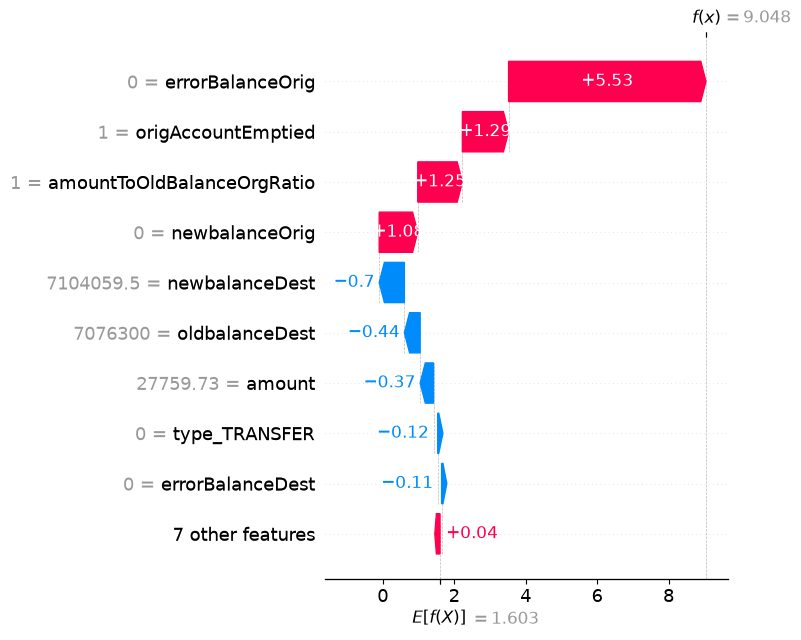

In [6]:
case_tp = X_sample.index.get_loc(tp_idx[0]) if len(tp_idx) else None
if case_tp is not None:
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values[case_tp],
            base_values=explainer.expected_value,
            data=X_sample.iloc[case_tp],
            feature_names=FEATURES,
        ),
        show=False,
    )
    plt.tight_layout()
    plt.savefig("../reports/shap_waterfall_true_positive.png", bbox_inches="tight")
    plt.show()

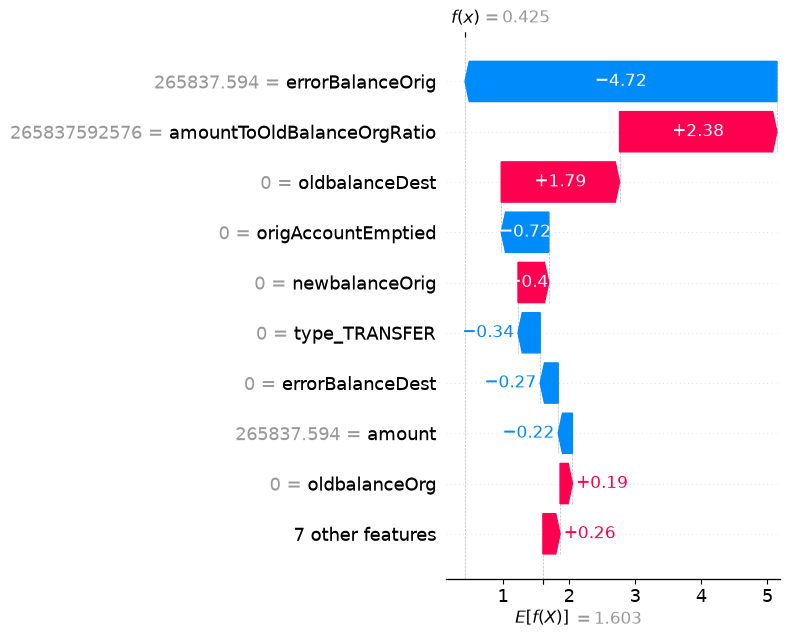

In [7]:
case_fp = X_sample.index.get_loc(fp_idx[0]) if len(fp_idx) else None
if case_fp is not None:
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values[case_fp],
            base_values=explainer.expected_value,
            data=X_sample.iloc[case_fp],
            feature_names=FEATURES,
        ),
        show=False,
    )
    plt.tight_layout()
    plt.savefig("../reports/shap_waterfall_false_positive.png", bbox_inches="tight")
    plt.show()

## 3.4 Interpretabilidad local — LIME (contraste con SHAP)

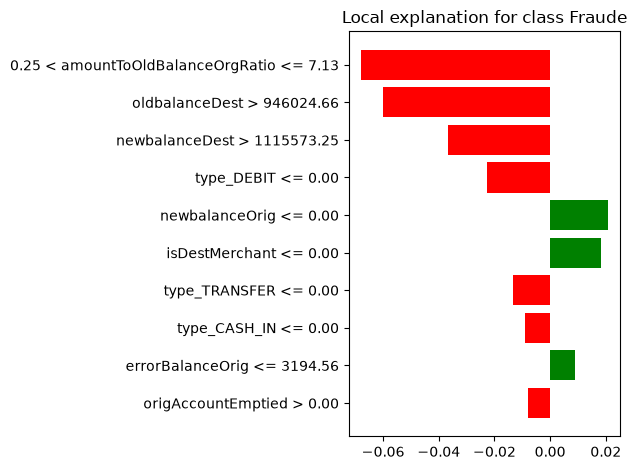

[('0.25 < amountToOldBalanceOrgRatio <= 7.13', -0.06788572779562803), ('oldbalanceDest > 946024.66', -0.06012310160668157), ('newbalanceDest > 1115573.25', -0.03666128905959387), ('type_DEBIT <= 0.00', -0.022693577866211307), ('newbalanceOrig <= 0.00', 0.02067077542838723), ('isDestMerchant <= 0.00', 0.018299403540520176), ('type_TRANSFER <= 0.00', -0.01344499666194185), ('type_CASH_IN <= 0.00', -0.00913070251869737), ('errorBalanceOrig <= 3194.56', 0.008783045980444177), ('origAccountEmptied > 0.00', -0.008014338518832077)]


In [8]:
lime_explainer = LimeTabularExplainer(
    X_train := X_sample.values,
    feature_names=FEATURES,
    class_names=["No fraude", "Fraude"],
    mode="classification",
    random_state=42,
)

if case_tp is not None:
    exp = lime_explainer.explain_instance(
        X_sample.iloc[case_tp].values, model.predict_proba, num_features=10
    )
    exp.as_pyplot_figure()
    plt.tight_layout()
    plt.savefig("../reports/lime_true_positive.png", bbox_inches="tight")
    plt.show()
    print(exp.as_list())

## 3.5 Contrafactual accionable (DiCE)

Para una transaccion marcada como fraude: ¿cual es el cambio minimo en sus
features para que el modelo la clasifique como legitima? Es util para dar
explicaciones accionables (p.ej. a un analista de riesgo).

In [9]:
import dice_ml

continuous_features = [f for f in FEATURES if not f.startswith("type_") and f not in (
    "origAccountEmptied", "isDestMerchant", "destBalanceUnknown"
)]

# DiCE castea las columnas continuas a float32 internamente y, si la moda de
# una columna es un numero grande y redondo (p.ej. amount=10,000,000.0), su
# representacion en notacion cientifica ("1e+07") rompe el parseo de
# precision decimal que DiCE hace por defecto (bug conocido de la libreria).
# Se evita dandole la precision explicita en vez de dejar que la infiera.
continuous_features_precision = {f: 2 for f in continuous_features}

dice_data = dice_ml.Data(
    dataframe=pd.concat([X_sample, y_sample.rename(TARGET_COL)], axis=1),
    continuous_features=continuous_features,
    continuous_features_precision=continuous_features_precision,
    outcome_name=TARGET_COL,
)
class _FloatCoercingModel:
    """DiCE genera candidatos de contrafactuales como DataFrame dtype=object
    (incluso para columnas int/bool de origen); XGBoost exige dtype numerico.
    """

    def __init__(self, model):
        self._model = model

    def predict_proba(self, X):
        return self._model.predict_proba(pd.DataFrame(X).astype(float))

    def predict(self, X):
        return self._model.predict(pd.DataFrame(X).astype(float))


dice_model = dice_ml.Model(model=_FloatCoercingModel(model), backend="sklearn")
dice_exp = dice_ml.Dice(dice_data, dice_model, method="random")

if len(tp_idx):
    query_instance = X_sample.loc[[tp_idx[0]]]
    counterfactuals = dice_exp.generate_counterfactuals(
        query_instance, total_CFs=3, desired_class="opposite"
    )
    counterfactuals.visualize_as_dataframe(show_only_changes=True)

  0%|          | 0/1 [00:00<?, ?it/s]

C:\venvs\dsrp_fraud\Lib\site-packages\dice_ml\explainer_interfaces\dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
C:\venvs\dsrp_fraud\Lib\site-packages\dice_ml\explainer_interfaces\dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
C:\venvs\dsrp_fraud\Lib\site-packages\dice_ml\explainer_interfaces\dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future 

100%|██████████| 1/1 [00:00<00:00,  2.60it/s]

100%|██████████| 1/1 [00:00<00:00,  2.59it/s]

Query instance (original outcome : 1)


,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,errorBalanceOrig,errorBalanceDest,amountToOldBalanceOrgRatio,origAccountEmptied,isDestMerchant,destBalanceUnknown,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,isFraud
0,27759.730469,27759.730469,0.0,7076300.0,7104059.5,0.0,0.0,1.0,1,0,0,0,1,0,0,0,1



Diverse Counterfactual set (new outcome: 0)


,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,errorBalanceOrig,errorBalanceDest,amountToOldBalanceOrgRatio,origAccountEmptied,isDestMerchant,destBalanceUnknown,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,isFraud
0,-,-,-,-,-,14359893.0,-,-,-,-,-,-,-,-,-,-,0.0
1,-,-,-,-,-,7488047.5,-,-,-,-,-,-,-,-,-,1.0,0.0
2,-,-,-,-,-,16212270.0,-,-,-,-,-,1.0,-,-,-,-,0.0


## 3.6 Conclusiones de interpretabilidad

_(Completar tras correr el notebook con el dataset real: resumir que
features dominan la decision del modelo a nivel global, si coincide con la
intuicion de negocio del Anexo 1 — errores de balance, vaciado de cuenta,
montos altos — y que tan consistentes son SHAP y LIME a nivel local.)_

Siguiente paso: [`4.0-monitoreo-drift.ipynb`](4.0-monitoreo-drift.ipynb).